# 02 · EMT-TF Expression — Chen 2020 NPC

The EMT-transcription-factor overlay is the **unconditional** final step, produced regardless
of how far the gate chain ran. Gate 1 was a **NO-GO** (the malignant compartment clusters by
patient, not into a sample-integrated continuous manifold), so no trajectory exists — this
notebook renumbers to **02** and overlays the detectable EMT-TFs on the preprocessing
embedding for reference, without asserting any arm/hub structure.

**EMT-TF selection (C1, Kürten lesson).** Score a candidate panel spanning the canonical
Snail/Zeb/Twist factors **and** the mesenchymal FOXC/PRRX families, gate on a ~3% detection
floor on this dataset, and rank the survivors by detection × variability. Do *not* restrict
to Snail/Zeb/Twist — on this dataset the canonical **SNAI1 falls below the floor**, while
**PRRX1/FOXC1** are the most-expressed factors.

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4))
pth_out = os.path.join(pth,'data','cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
adata = sc.read_h5ad(os.path.join(pth_out,'processed.h5ad'))
print('processed embedding:', adata.n_obs, 'malignant cells |', adata.obs['sample'].nunique(),'samples')
print('Gate 1:', adata.uns['gate1']['decision'])

processed embedding: 3674 malignant cells | 8 samples
Gate 1: NO-GO


### Detection-gated EMT-TF panel

In [ ]:
raw = adata.raw.to_adata()
cand = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
rows=[]
for g in cand:
    if g in raw.var_names:
        x=np.asarray(raw[:,g].X.todense()).ravel()
        det=(x>0).mean(); rows.append((g,det,float(x.std())))
tab=pd.DataFrame(rows,columns=['TF','detect_frac','std']).sort_values('detect_frac',ascending=False)
tab['passes_3pct']=tab['detect_frac']>=0.03
tab['score']=tab['detect_frac']*tab['std']
print(tab.round(3).to_string(index=False))
panel = tab[tab['passes_3pct']].sort_values('score',ascending=False)['TF'].tolist()
print('\ncanonical SNAI1 detect =', round(float(tab.set_index('TF').loc['SNAI1','detect_frac']),3),
      '-> below floor; a Snail/Zeb/Twist-only panel would miss the signal')
print('selected EMT-TFs (>=3% detection, ranked by detection x variability):', panel[:6])

    TF  detect_frac   std  passes_3pct  score
 PRRX1        0.623 0.350         True  0.218
 SNAI2        0.244 0.175         True  0.043
 FOXC1        0.133 0.108         True  0.014
  ZEB2        0.130 0.089         True  0.012
  ZEB1        0.073 0.065         True  0.005
TWIST2        0.059 0.067         True  0.004
 FOXC2        0.043 0.071         True  0.003
 PRRX2        0.023 0.046        False  0.001
 SNAI1        0.016 0.025        False  0.000
TWIST1        0.010 0.039        False  0.000

canonical SNAI1 detect = 0.016 -> below floor; a Snail/Zeb/Twist-only panel would miss the signal
selected EMT-TFs (>=3% detection, ranked by detection x variability): ['PRRX1', 'SNAI2', 'FOXC1', 'ZEB2', 'ZEB1', 'TWIST2']


### Overlay the selected EMT-TFs on the malignant embedding

Colored on the preprocessing UMAP. **Caveat:** Gate 1 was NO-GO, so this embedding is
patient-structured, not a cell-state trajectory — the overlay is descriptive only.

saved expression.pdf with TFs: ['PRRX1', 'SNAI2', 'FOXC1', 'ZEB2', 'ZEB1', 'TWIST2']


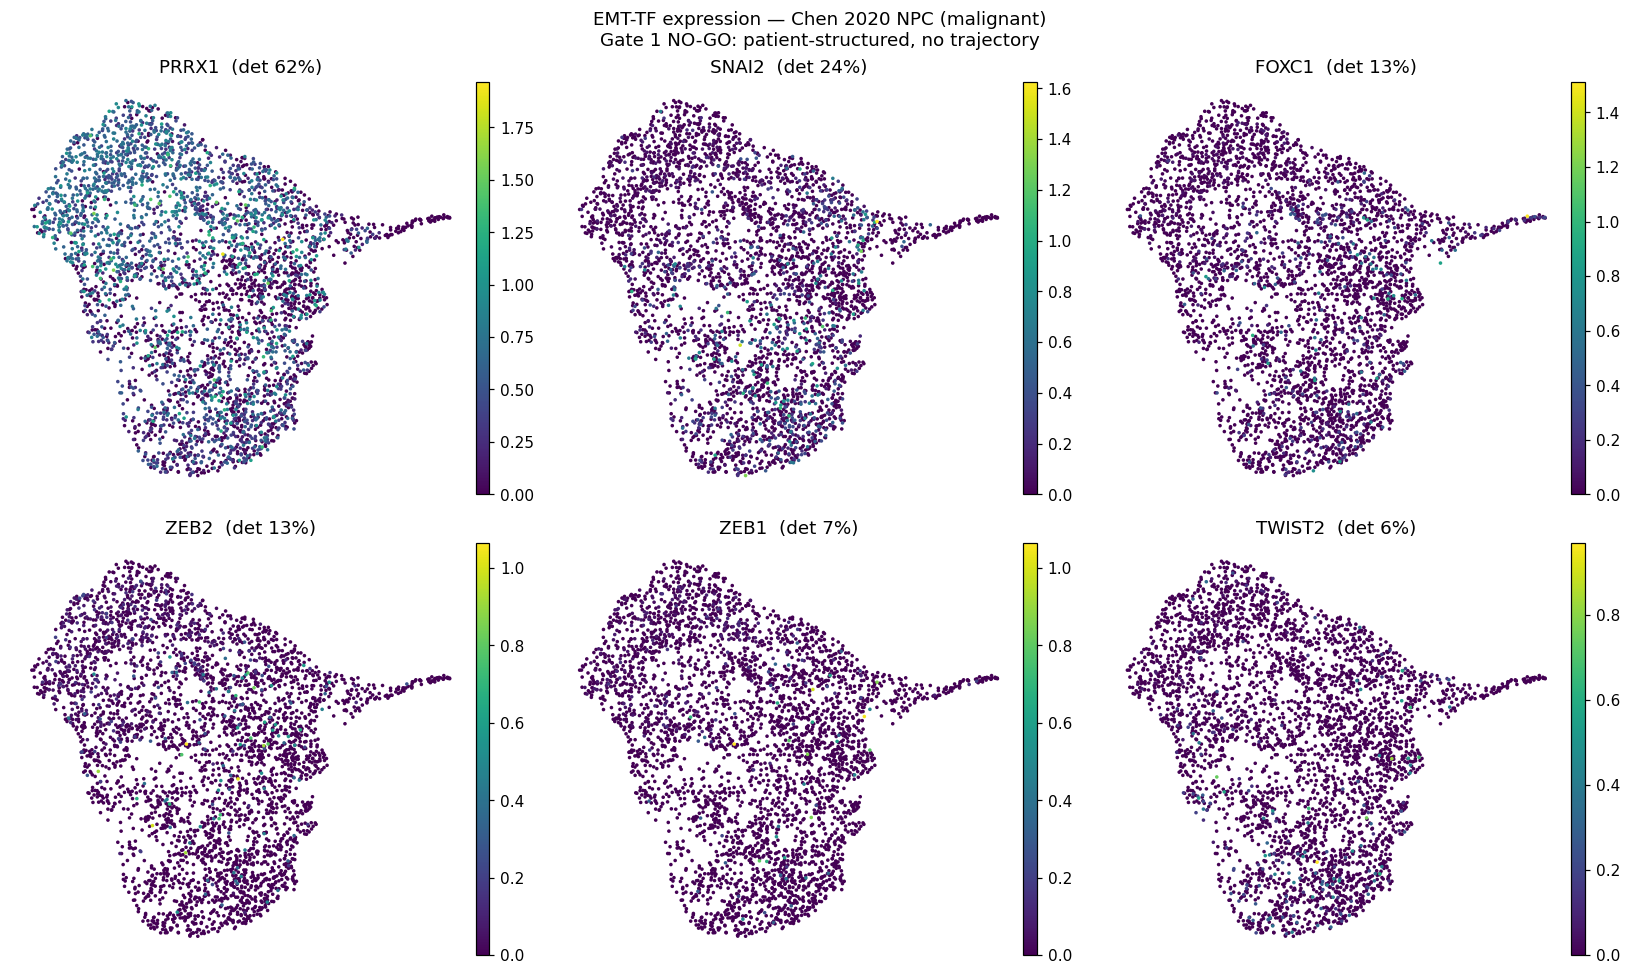

In [ ]:
genes = panel[:6]
# rebuild a full-gene view (log-norm) from .raw so the TFs are colorable by var name
full = adata.raw.to_adata(); full.obsm['X_umap'] = adata.obsm['X_umap']
fig,axes=plt.subplots(2,3,figsize=(15,9))
for ax,g in zip(axes.ravel(),genes):
    det=(np.asarray(full[:,g].X.todense()).ravel()>0).mean()
    sc.pl.umap(full,color=g,ax=ax,show=False,cmap='viridis',size=22,frameon=False,
               title=f'{g}  (det {det:.0%})')
for ax in axes.ravel()[len(genes):]: ax.axis('off')
fig.suptitle('EMT-TF expression — Chen 2020 NPC (malignant)\nGate 1 NO-GO: patient-structured, no trajectory',size=12)
fig.tight_layout(); fig.savefig(os.path.join(pth_fig,'expression.pdf'),bbox_inches='tight'); plt.show()
print('saved expression.pdf with TFs:', genes)

### Summary

The detectable EMT-TF program on Chen 2020 malignant cells is led by **PRRX1** and **SNAI2**,
with **FOXC1/ZEB2** contributing — i.e. mesenchymal-family factors, not the canonical SNAI1
(below the detection floor). Because Gate 1 was a NO-GO, these are shown on the patient-
structured embedding for reference only; no arm-specific or trajectory-terminus assignment is
made (that would require a sample-integrated continuous manifold, which this compartment does
not yield).